# 1E. FNN - Sign Language MNIST
FNN baseline.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers

In [2]:
train = pd.read_csv("../datasets/FNN and CNN/Sign Language MNIST/sign_mnist_train.csv")
test = pd.read_csv("../datasets/FNN and CNN/Sign Language MNIST/sign_mnist_test.csv")

y_train = train["label"].to_numpy()
y_test = test["label"].to_numpy()
x_train = train.drop(columns="label").to_numpy()
x_test = test.drop(columns="label").to_numpy()

print(x_train.shape, x_test.shape)

(27455, 784) (7172, 784)


In [3]:
model = keras.Sequential([
    layers.Input(shape=(784,)),
    layers.Rescaling(1./255),
    layers.Dense(128, activation="relu"),
    layers.Dense(25, activation="softmax"),
])
model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 25)             │         3,225 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 103,705 (405.10 KB)

 Trainable params: 103,705 (405.10 KB)

 Non-trainable params: 0 (0.00 B)

In [4]:
history = model.fit(x_train, y_train, validation_data=(x_test, y_test), epochs=5)

Epoch 1/5
858/858 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.4130 - loss: 2.0034 - val_accuracy: 0.5611 - val_loss: 1.4755
Epoch 2/5
858/858 ━━━━━━━━━━━━━━━━━━━━ 1s 910us/step - accuracy: 0.6628 - loss: 1.1397 - val_accuracy: 0.6170 - val_loss: 1.2940
Epoch 3/5
858/858 ━━━━━━━━━━━━━━━━━━━━ 1s 908us/step - accuracy: 0.7474 - loss: 0.8471 - val_accuracy: 0.6516 - val_loss: 1.1631
Epoch 4/5
858/858 ━━━━━━━━━━━━━━━━━━━━ 1s 904us/step - accuracy: 0.8021 - loss: 0.6793 - val_accuracy: 0.6465 - val_loss: 1.1119
Epoch 5/5
858/858 ━━━━━━━━━━━━━━━━━━━━ 1s 907us/step - accuracy: 0.8448 - loss: 0.5473 - val_accuracy: 0.6711 - val_loss: 1.0590


In [5]:
loss, acc = model.evaluate(x_test, y_test)
print(f"test loss: {loss:.4f}  test accuracy: {acc:.4f}")

  1/225 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.7812 - loss: 0.5648

115/225 ━━━━━━━━━━━━━━━━━━━━ 0s 440us/step - accuracy: 0.6655 - loss: 1.0864

225/225 ━━━━━━━━━━━━━━━━━━━━ 0s 460us/step - accuracy: 0.6711 - loss: 1.0590


test loss: 1.0590  test accuracy: 0.6711


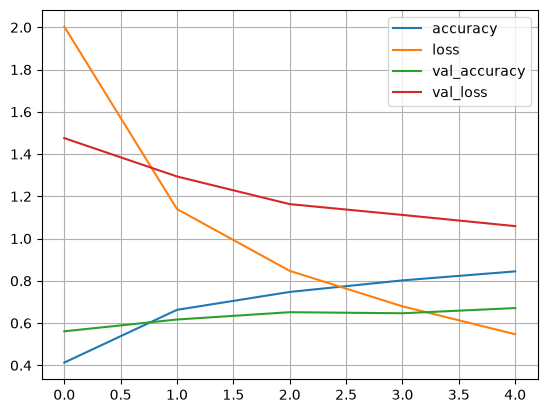

In [6]:
for k, v in history.history.items():
    plt.plot(v, label=k)
plt.legend()
plt.grid()
plt.show()